In [57]:
import qiskit
import qiskit_ibm_runtime
import pylatexenc

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit.circuit import Parameter
from qiskit.circuit.library import UGate
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2

import numpy as np
from numpy import pi

from itertools import product

from matplotlib import pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

<h1>Accurate CNOT from 0 to 1 and 1 to 2</h1>

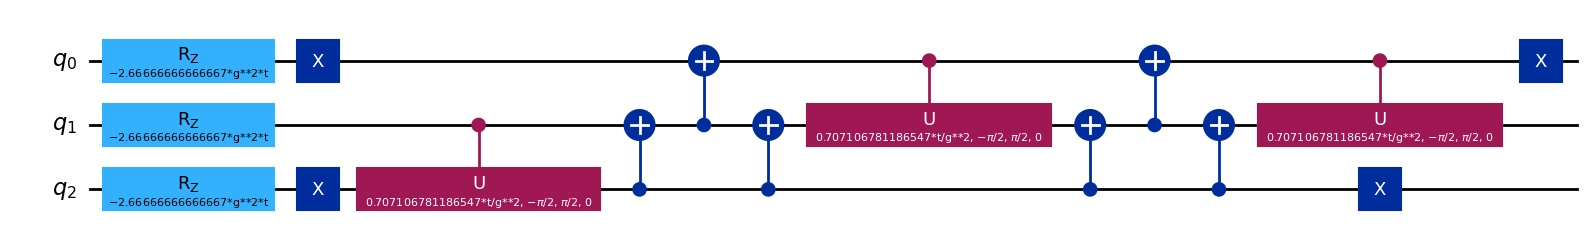

In [59]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

def one_step(n, N):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(-theta_E/N, q)

    for i in range(1, n - 1):
        # Flip controls from |0⟩ to |1⟩
        qc.x(i - 1)
        qc.x(i + 1)

        controlled_u = UGate(theta_B/N, -pi/2, pi/2).control(1)

        qc.append(controlled_u, [i, i + 1])
        qc.cx(i + 1, i)
        qc.cx(i, i - 1)
        qc.cx(i + 1, i)

        qc.append(controlled_u, [i - 1, i])
        qc.cx(i + 1, i)
        qc.cx(i, i - 1)
        qc.cx(i + 1, i)

        qc.append(controlled_u, [i - 1, i])

        # Flip back controls
        qc.x(i - 1)
        qc.x(i + 1)

    return qc

def N_steps_compose(n, N):
    one_step_circuit = one_step(n, N)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

n = 3
N = 1
full_circuit = N_steps_compose(n, N)
full_circuit.draw("mpl")

In [60]:
observables_labels = ["IZI", "ZZI", "IZZ", "ZIZ"]
observables = [SparsePauliOp(label) for label in observables_labels]

In [61]:
def plot_measurement(n, N):
    # Run on Simulator
    qc = N_steps_compose(n, N)
    qc = qc.assign_parameters({g:1., t:1.})

    backend = FakeAlmadenV2()
    estimator = Estimator(backend)
 
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_circuit = pm.run(qc)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in observables
    ]
 
    job = estimator.run([(isa_circuit, mapped_observables)])
    result = job.result()
 
    job_result = job.result()
 
    pub_result = job.result()[0]

    # Plot Graph
    values = pub_result.data.evs
    errors = pub_result.data.stds

    plt.plot(observables_labels, values, "-o")
    plt.xlabel("Observables")
    plt.ylabel("Values")
    plt.tight_layout()
    plt.title(f"Measurement for N = {N} with {n} qubits with Accurate CNOTs")
    plt.savefig(f'Accurate CNOT for {N} Steps.png')
    plt.show()

<h1>N = 1</h1>

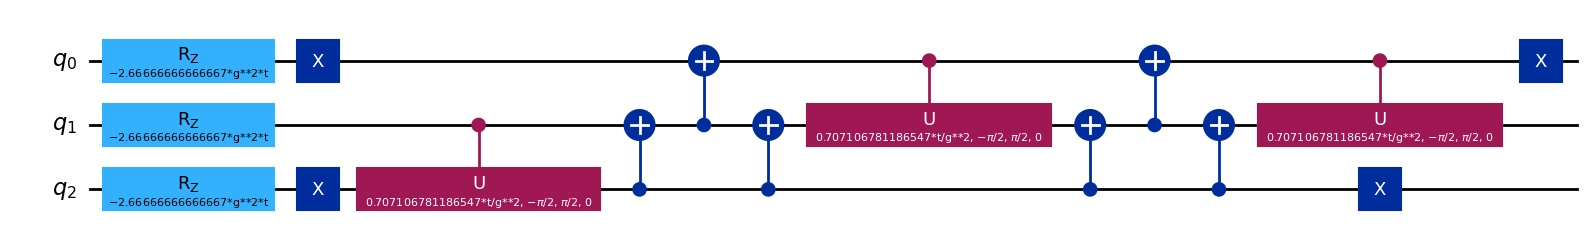

In [63]:
n = 3
N = 1
full_circuit = N_steps_compose(n, N)
full_circuit.draw("mpl")

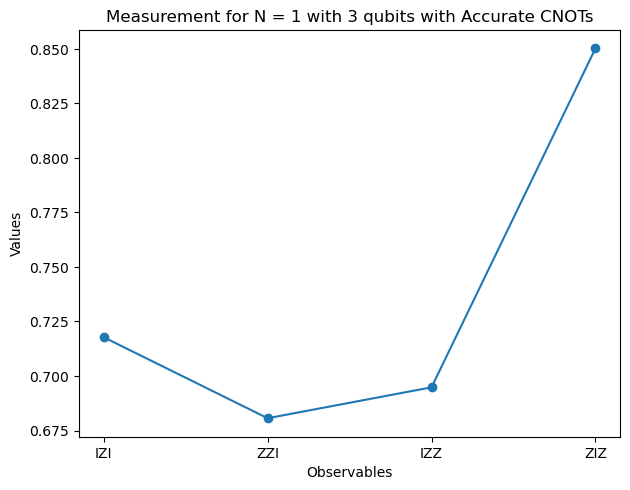

In [64]:
plot_measurement(n, N)

<h1>N = 2</h1>

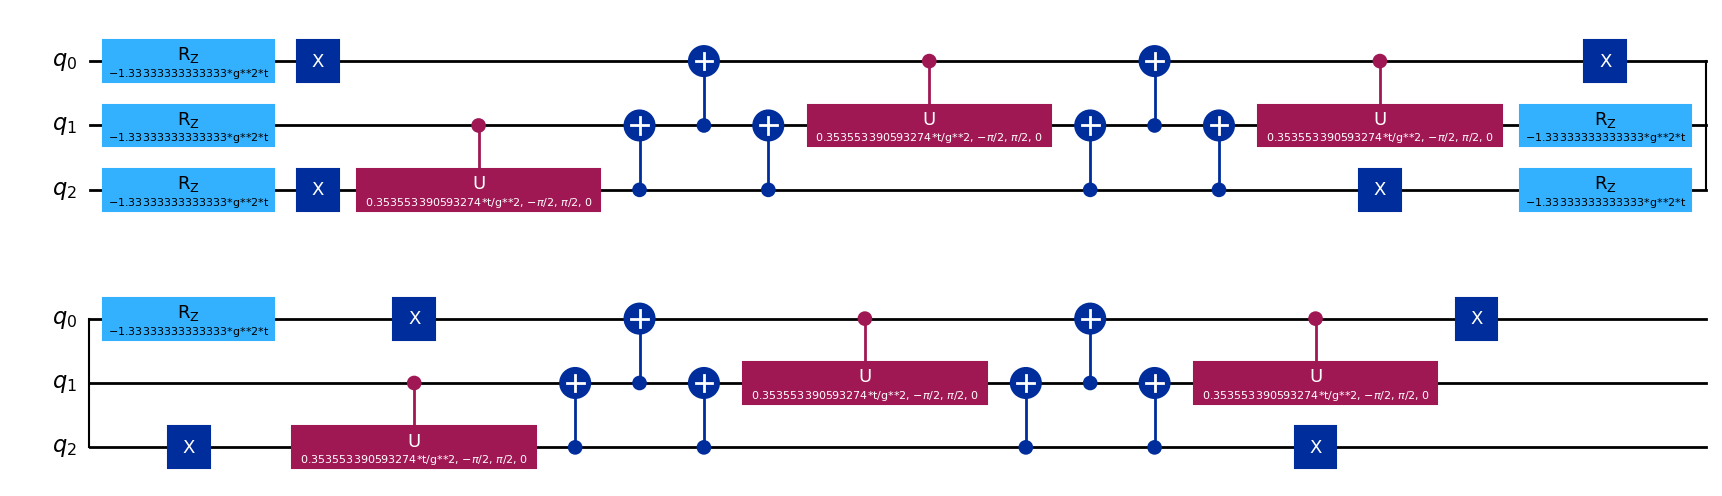

In [66]:
n = 3
N = 2
full_circuit = N_steps_compose(n, N)
full_circuit.draw("mpl")

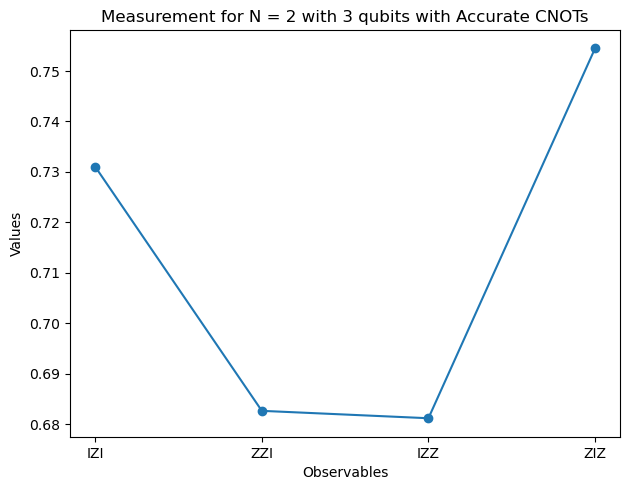

In [67]:
plot_measurement(n, N)

<h1>For Loop for N = 10</h1>

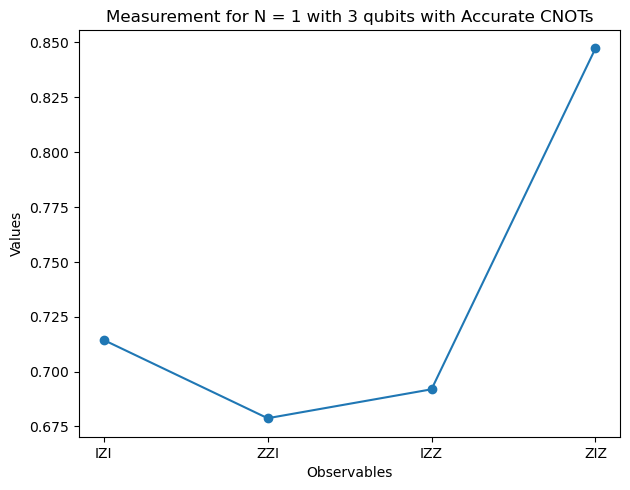

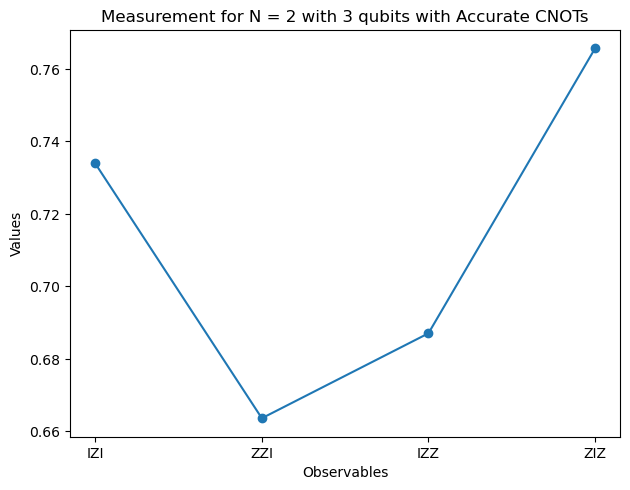

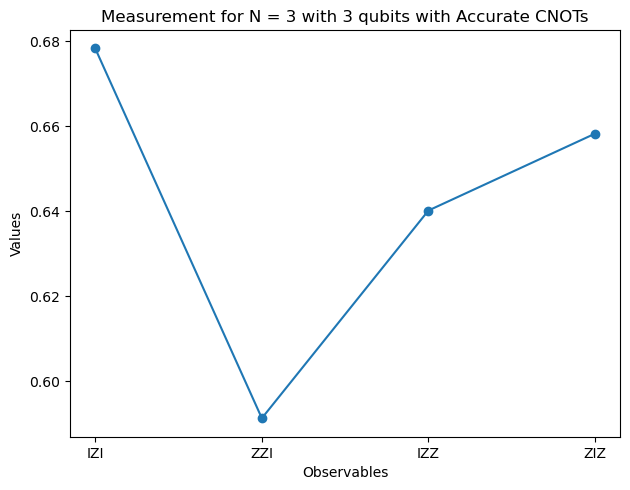

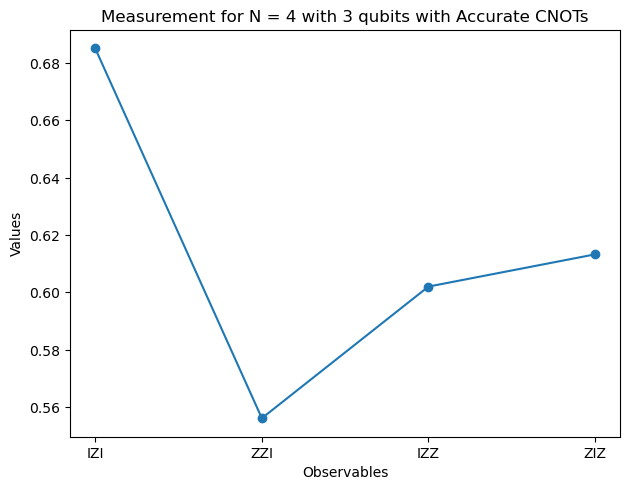

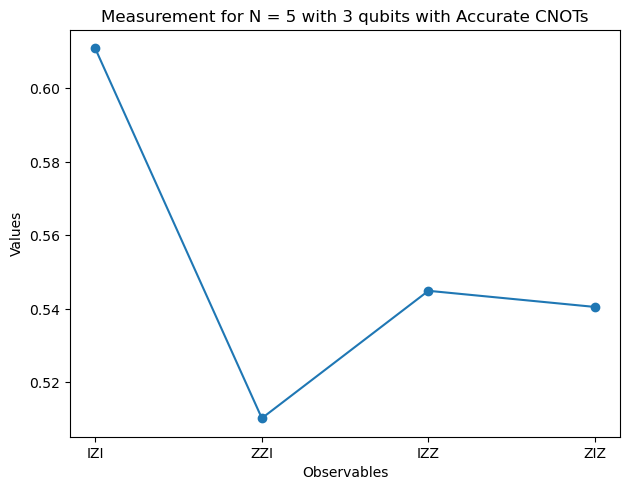

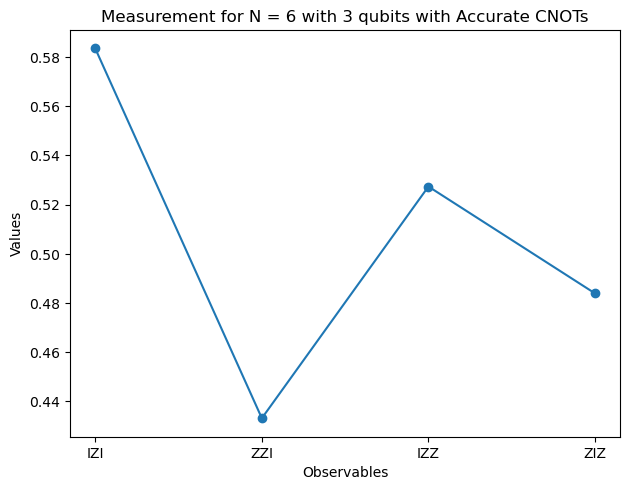

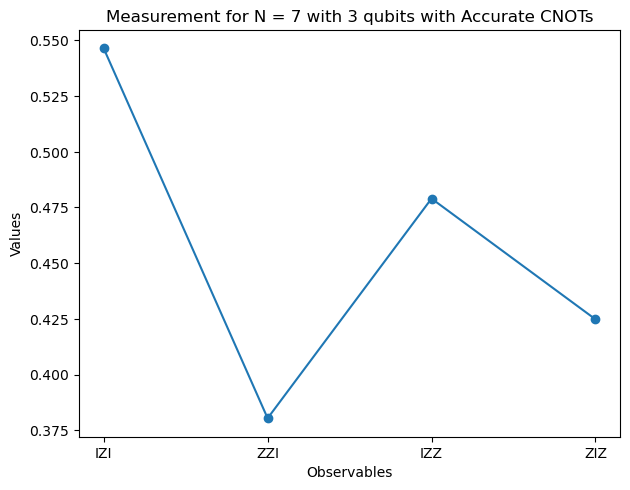

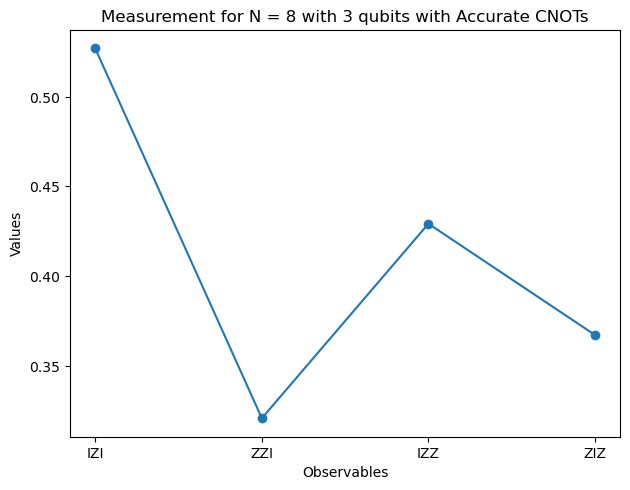

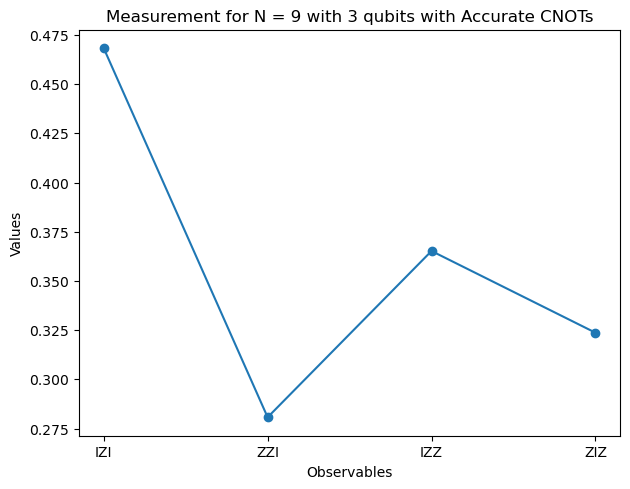

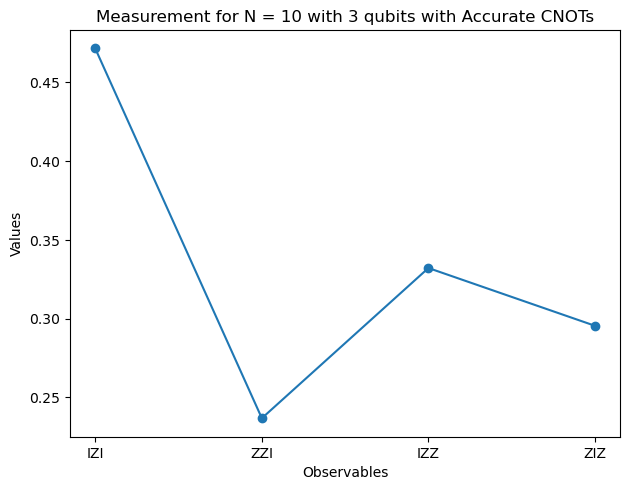

In [69]:
for i in np.arange(1, 11):
    plot_measurement(3, i)

In [70]:
def plot_measurement_loop(n, N):
    # Run on Simulator
    qc = N_steps_compose(n, N)
    qc = qc.assign_parameters({g:1., t:1.})

    backend = FakeAlmadenV2()
    estimator = Estimator(backend)
 
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_circuit = pm.run(qc)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in observables
    ]
 
    job = estimator.run([(isa_circuit, mapped_observables)])
    result = job.result()
 
    job_result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = observables_labels
    return labels, values

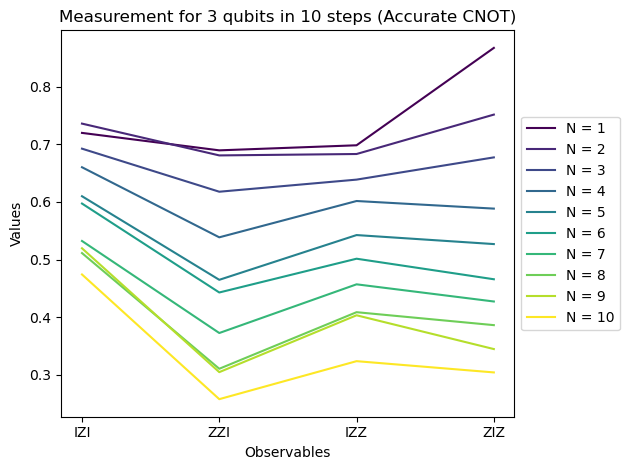

In [71]:
colors = cm.viridis(np.linspace(0, 1, 10))  # 10 colors evenly spaced

for idx, i in enumerate(np.arange(1, 11)):
    labels, values = plot_measurement_loop(3, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 10 steps (Accurate CNOT)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f'Accurate CNOT for 3 Qubits in 10 Steps.png')
plt.show()

<h1>For Loop for N = 20</h1>

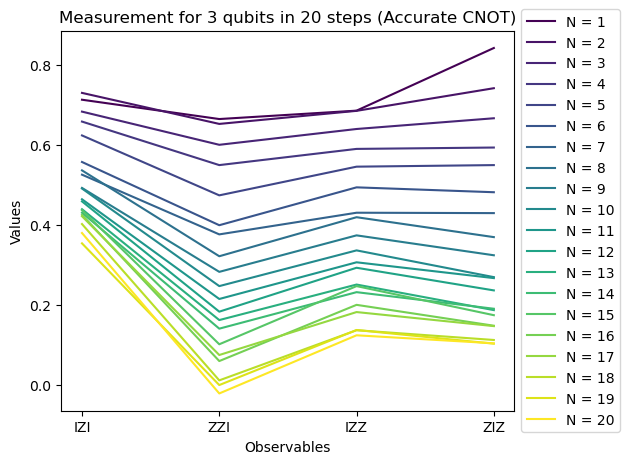

In [73]:
colors = cm.viridis(np.linspace(0, 1, 20))

for idx, i in enumerate(np.arange(1, 21)):
    labels, values = plot_measurement_loop(3, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 20 steps (Accurate CNOT)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f'Accurate CNOT for 3 Qubits in 20 Steps.png')
plt.show()

<h1>Traditional CNOT from 0 to 2</h1>

In [75]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

def one_step_trad(n, N):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(-theta_E/N, q)

    for i in range(1, n - 1):       
        qc.x(i - 1)
        qc.x(i + 1)
        
        qc.mcrx(2 * theta_B/N, [i - 1, i + 1], i)

        qc.x(i - 1)
        qc.x(i + 1)
    return qc

def N_steps_compose_trad(n, N):
    one_step_circuit = one_step_trad(n, N)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

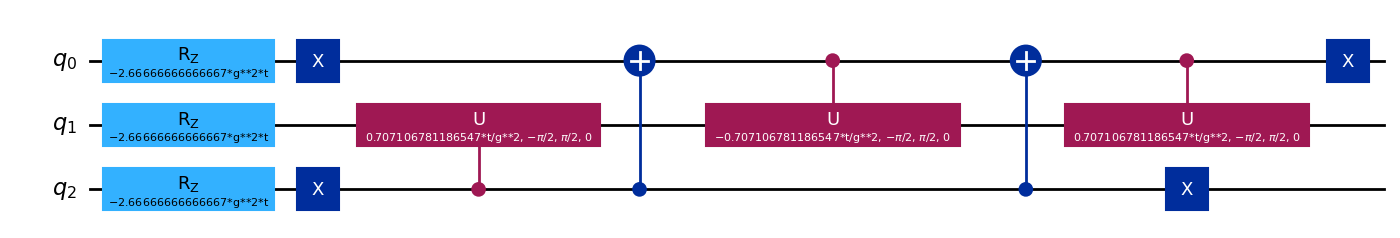

In [76]:
n = 3
N = 1
full_circuit = N_steps_compose_trad(n, N)
full_circuit.draw("mpl")

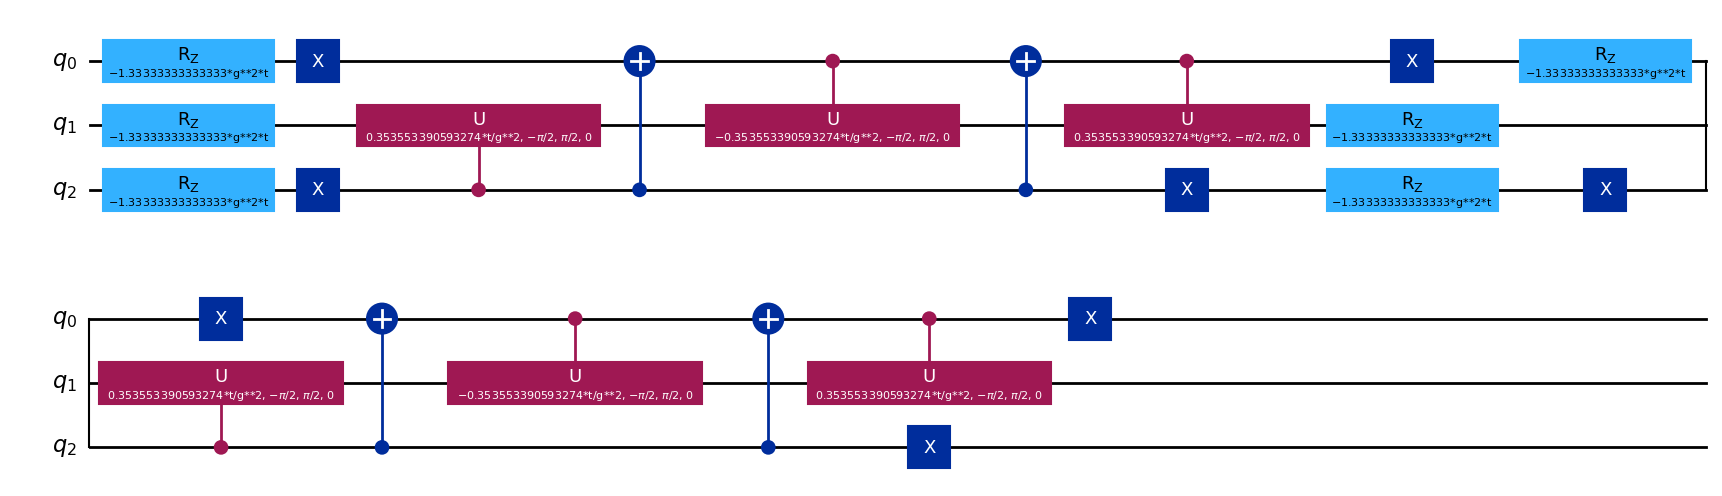

In [77]:
n = 3
N = 2
full_circuit = N_steps_compose_trad(n, N)
full_circuit.draw("mpl")

In [78]:
def plot_measurement_trad(n, N):
    # Run on Simulator
    qc = N_steps_compose_trad(n, N)
    qc = qc.assign_parameters({g:1., t:1.})

    backend = FakeAlmadenV2()
    estimator = Estimator(backend)
 
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_circuit = pm.run(qc)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in observables
    ]
 
    job = estimator.run([(isa_circuit, mapped_observables)])
    result = job.result()
 
    job_result = job.result()
 
    pub_result = job.result()[0]

    # Plot Graph
    values = pub_result.data.evs
    errors = pub_result.data.stds

    plt.plot(observables_labels, values, "-o")
    plt.xlabel("Observables")
    plt.ylabel("Values")
    plt.tight_layout()
    plt.title(f"Measurement for N = {N} with {n} qubits with Traditional CNOTs")
    plt.savefig(f'Traditional CNOT for {N} Steps.png')
    plt.show()

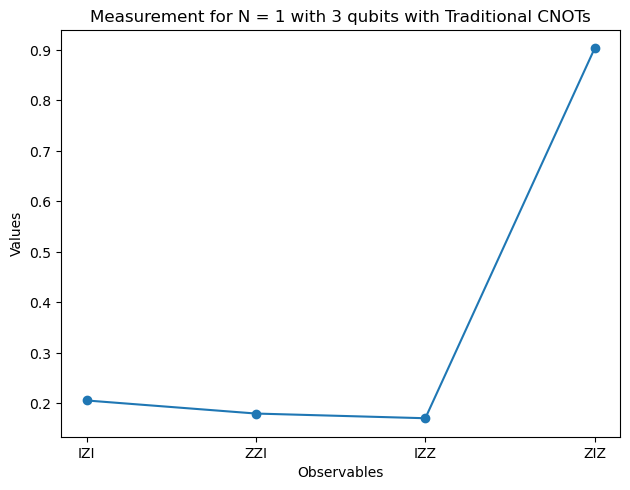

In [79]:
plot_measurement_trad(3, 1)

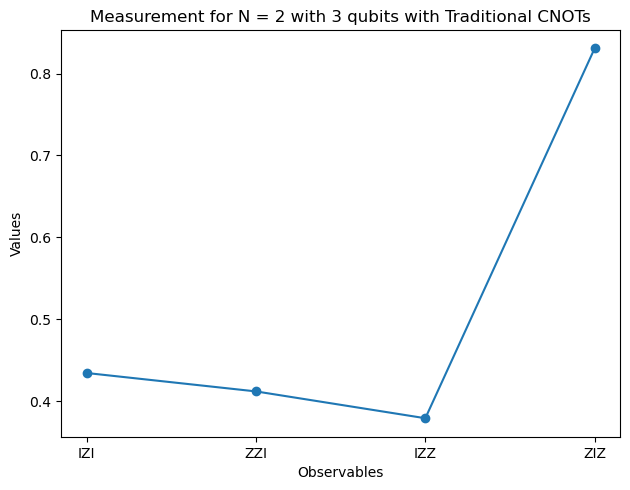

In [80]:
plot_measurement_trad(3, 2)

<h1>Traditional 3 qubits with for loop N = 10, 20</h1>

In [82]:
def plot_measurement_loop_trad(n, N):
    # Run on Simulator
    qc = N_steps_compose_trad(n, N)
    qc = qc.assign_parameters({g:1., t:1.})

    backend = FakeAlmadenV2()
    estimator = Estimator(backend)
 
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_circuit = pm.run(qc)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in observables
    ]
 
    job = estimator.run([(isa_circuit, mapped_observables)])
    result = job.result()
 
    job_result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = observables_labels
    return labels, values

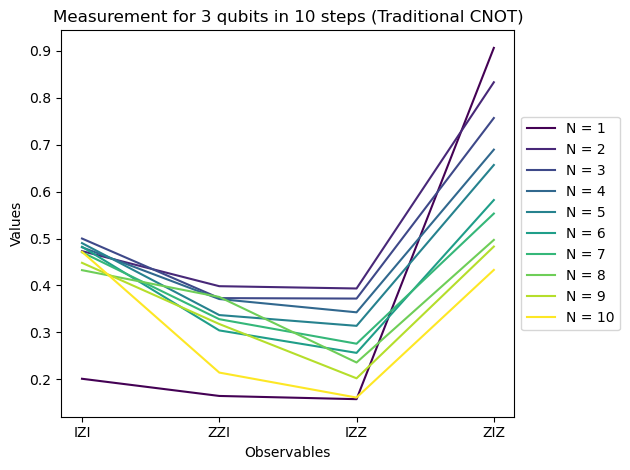

In [83]:
colors = cm.viridis(np.linspace(0, 1, 10))  # 10 colors evenly spaced

for idx, i in enumerate(np.arange(1, 11)):
    labels, values = plot_measurement_loop_trad(3, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 10 steps (Traditional CNOT)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f'Traditional CNOT for 3 Qubits in 10 Steps.png')
plt.show()

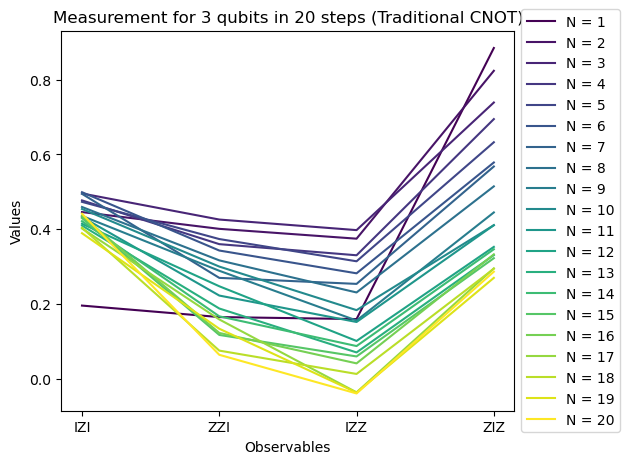

In [84]:
colors = cm.viridis(np.linspace(0, 1, 20))

for idx, i in enumerate(np.arange(1, 21)):
    labels, values = plot_measurement_loop_trad(3, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 20 steps (Traditional CNOT)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f'Traditional CNOT for 3 Qubits in 20 Steps.png')
plt.show()

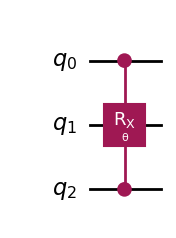

In [85]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import RXGate
from qiskit.circuit import Parameter

theta = Parameter("θ")
qc = QuantumCircuit(3)

# Apply R_x(θ) on qubit 1, controlled by qubits 0 and 2
controlled_rx = RXGate(theta).control(2)  # 2 control qubits

# Control order: [q0, q2] → target: q1
qc.append(controlled_rx, [0, 2, 1])

qc.draw("mpl")